# Contouring

In [9]:
# conda vis2
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np

PROJECT_ROOT = Path().resolve().parent.parent
sys.path.append(str(PROJECT_ROOT))

plt.style.use('seaborn-v0_8-talk')

In [5]:
import src.Retrieval as retrieval
from src.ExperimentSet import ExperimentSet
from src.utils.util import set_labels

In [41]:
def get_pixels(r, i, mask_name='ray_containment', mask_vals=[0,1,2]):
    misr = r.obs['MISR']['sensor_list'][i]
    at3d = r.sensors_retrieval['MISR']['sensor_list'][i]
    mask = np.isin(r.masks['MISR']['sensor_list'][i][mask_name].data, mask_vals)
    x = misr.ray_x.data[mask]
    y = misr.ray_y.data[mask]
    m = misr.brf.data[mask]
    a = at3d.brf.data[mask]
    return misr, at3d, mask, x, y, m, a

def plot_F_vs_MISR_single_cam(f, ax, r, mask_name, mask_vals, plot_kwargs, diff_kwargs, contr_kwargs, i=0, contr=True, dom_boarder=False, correction=0, text_y=22):
    (misr, at3d, mask, x, y, m, a) = get_pixels(r, i, mask_name, mask_vals)
    a = a-correction
    ax[0].tricontourf(x, y, m, **plot_kwargs)
    c1 = ax[1].tricontourf(x, y, a, **plot_kwargs)
    c2 = ax[2].tricontourf(x, y, a-m, **diff_kwargs)
    # c2 = ax[2].tricontourf(x, y, 100*(a-m)/m, **diff_kwargs)
    if(contr):
        ax[0].tricontour(x, y, a-m, **contr_kwargs)
        ax[1].tricontour(x, y, a-m, **contr_kwargs)
        tmp = contr_kwargs.copy()
        tmp.pop('cmap')
        ax[2].tricontour(x, y, a-m, colors='k', **tmp)
    ticks = [0.0, 4.4, 8.8, 13.2, 17.6]
    box_kwargs = {'ls':'--', 'lw':0.7, 'c':'r'}
    for a in ax.flat:
        if(dom_boarder):
            a.plot([0, 0], [0, 17.6], **box_kwargs)
            a.plot([0, 17.6], [0, 0], **box_kwargs)
            a.plot([17.6, 17.6], [0, 17.6], **box_kwargs)
            a.plot([0, 17.6], [17.6, 17.6], **box_kwargs)
        a.set_xticks(ticks)
        a.set_xticklabels(ticks, rotation=45)
        a.set_yticks(ticks)
    return c1, c2

In [7]:
version = 'V11'
es_dir = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / version
exset = ExperimentSet(es_dir)
exset.set_retrieval_list()
exset.load_retrievals(iteration=-1, extinction_th=[0.3, np.inf])

In [23]:
vrange = 0.26
plot_kwargs = {
    'cmap':'gray',
    'vmin':0,
    'vmax':0.4,
    'levels':np.linspace(0, 0.4, 50)
}
diff_kwargs = {
    'cmap':'RdBu_r',
    'vmin':-vrange,
    'vmax':vrange,
    'levels':np.linspace(-vrange, vrange, 100)
}
contr_kwargs = diff_kwargs.copy()
contr_kwargs['levels'] = np.array([0.04])

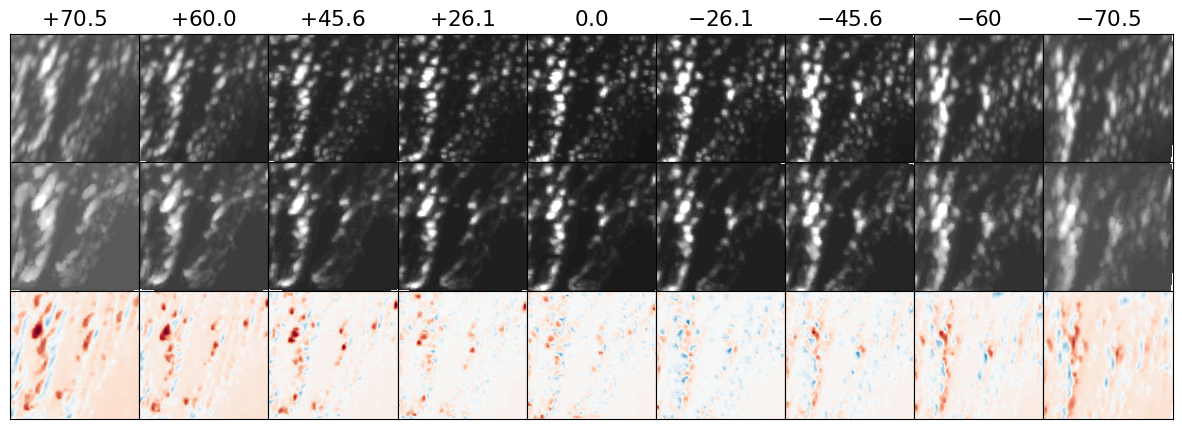

In [55]:
vrange = 0.22
plot_kwargs = {
    'cmap':'gray',
    'vmin':0,
    'vmax':0.36,
    'levels':np.linspace(0, 0.4, 50)
}
diff_kwargs = {
    'cmap':'RdBu_r',
    'vmin':-vrange,
    'vmax':vrange,
    'levels':np.linspace(-vrange, vrange, 100)
}
contr_kwargs = diff_kwargs.copy()
contr_kwargs['levels'] = np.array([0.04])
contr_kwargs['linewidths'] = 1

titles = [r'$+70.5$', r'$+60.0$', r'$+45.6$',r'$+26.1$',r'$0.0$',r'$-26.1$',r'$-45.6$',r'$-60$',r'$-70.5$']

f, ax = plt.subplots(3, 9, figsize=(15,5), sharex=True, sharey=True)
f.subplots_adjust(wspace=0.0, hspace=0.0)

# ret = 'unconstrained'
# ret = 'CTM_unc'
ret = 'CTP_unc'
# ret = 'default'

for i in range(9):
    c1, c2 = plot_F_vs_MISR_single_cam(
            f,
            ax[:,i],
            exset.get_retrieval(ret),
            'ray_containment',
            [0,1,2],
            plot_kwargs,
            diff_kwargs,
            contr_kwargs,
            i=i,
            contr=False,
            dom_boarder=False,
            correction=0.0,
            text_y=22
        )
    ax[0,i].set_title(titles[i])

for a in ax.flatten():
    # a.set_xlim([-1.1, 18.7])
    # a.set_ylim([-4.0, 21.6])
    a.set_xlim([0, 17.6])
    a.set_ylim([0, 17.6])
    a.set_xticks([])
    a.set_yticks([])